# Chapter 02: The Price of Optimism — Python Laboratory
### *Kullback-Leibler Divergence, Gibbs' Inequality & The Asymmetry of Forward vs. Reverse KL*

**[Course Home](../README.md) | [Conceptual Track](../conceptual/02_relative_entropy_and_prior_penalties.ipynb) | [Prev: Ch 01: Quantifying Uncertainty (Python)](01_quantifying_uncertainty_entropy_and_bayes.ipynb) | [Next: Ch 03: Where Fleet Priors Come From (Python)](03_maximum_entropy_priors.ipynb)**

---

## 1. Overview & Setup

In this laboratory, we implement:
1. **Cross-Entropy & Kullback-Leibler Divergence** from scratch with vectorized NumPy functions.
2. **The Optimistic Tech Lead Case Study**: Simulating the cost of deploying a 1-in-1,000 belief model against a 5% flaky reality.
3. **Gibbs' Inequality Monte Carlo Verification**: Testing 1,000 random Dirichlet distributions to confirm that $D_{\text{KL}}(P \parallel Q) \ge 0$ strictly holds.
4. **The Asymmetry of Forward vs. Reverse KL**: Visualizing mode-seeking vs. mean-seeking behavior on bimodal distributions.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize

# Style configuration
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 10
plt.rcParams['figure.dpi'] = 120

print("Environment initialized successfully.")


Environment initialized successfully.


---

## 2. Implementation: Shannon Entropy, Cross-Entropy & KL Divergence

We implement numerical functions in bits, handling zero-probabilities safely using boolean masking.


In [2]:
def entropy(p):
    # Shannon entropy H(P) in bits
    p = np.asarray(p, dtype=np.float64) / np.sum(p)
    mask = p > 1e-15
    return -float(np.sum(p[mask] * np.log2(p[mask])))

def cross_entropy(p, q):
    # Cross-entropy H(P, Q) in bits
    p = np.asarray(p, dtype=np.float64) / np.sum(p)
    q = np.asarray(q, dtype=np.float64) / np.sum(q)
    mask = p > 1e-15
    return -float(np.sum(p[mask] * np.log2(q[mask])))

def kl_divergence(p, q):
    # Relative entropy D_KL(P || Q) in bits
    p = np.asarray(p, dtype=np.float64) / np.sum(p)
    q = np.asarray(q, dtype=np.float64) / np.sum(q)
    mask = p > 1e-15
    return float(np.sum(p[mask] * np.log2(p[mask] / q[mask])))

print("Information-theoretic functions validated.")


Information-theoretic functions validated.


---

## 3. Case Study: The Optimistic Tech Lead

We simulate the exact billing integration test from Section 1:
* **Reality $P$**: $95\%$ Pass, $5\%$ Fail ($P = [0.95, 0.05]$)
* **Tech Lead Belief $Q$**: $99.9\%$ Pass, $0.1\%$ Fail ($Q = [0.999, 0.001]$)


In [3]:
p_real = np.array([0.95, 0.05])     # [Pass, Fail]
q_belief = np.array([0.999, 0.001]) # [Pass, Fail]

h_true = entropy(p_real)
ce_lead = cross_entropy(p_real, q_belief)
dkl_penalty = kl_divergence(p_real, q_belief)

print("=" * 65)
print("       THE OPTIMISTIC TECH LEAD: INFORMATION COST BREAKDOWN")
print("=" * 65)
print(f"1. Minimum Theoretical Bitrate H(P):      {h_true:.4f} bits/build")
print(f"2. Actual Flawed Code Length H(P, Q):     {ce_lead:.4f} bits/build")
print(f"3. Relative Entropy Penalty D_KL(P || Q): {dkl_penalty:.4f} bits/build")
print("-" * 65)
print(f"Identity Verification: H(P, Q) == H(P) + D_KL(P || Q)?")
print(f"  {ce_lead:.6f} == {h_true + dkl_penalty:.6f} --> {np.isclose(ce_lead, h_true + dkl_penalty)}")
print("=" * 65)


       THE OPTIMISTIC TECH LEAD: INFORMATION COST BREAKDOWN
1. Minimum Theoretical Bitrate H(P):      0.2864 bits/build
2. Actual Flawed Code Length H(P, Q):     0.4997 bits/build
3. Relative Entropy Penalty D_KL(P || Q): 0.2133 bits/build
-----------------------------------------------------------------
Identity Verification: H(P, Q) == H(P) + D_KL(P || Q)?
  0.499660 == 0.499660 --> True


### Operational Impact: What "Spending Bits" Means in Production

The difference between what the team spends ($0.4997\text{ bits/build}$) and
what is optimal ($0.2864\text{ bits/build}$) is the **Relative Entropy Tax**:
$D_{\text{KL}}(P \parallel Q) = 0.2133\text{ bits/build}$.

#### Why Not Just Use Raw Probabilities?

A pragmatic engineer might ask: *Why translate probabilities into bits at
all? If our test fails $5\%$ of the time, then out of $1{,}000$ builds we
expect $0.05 \times 1{,}000 = 50$ failures. If we need to provision CI runner
capacity, we size a $5\%$ retry budget. Why bother converting $p$ into
$-\log_2(p)$ instead of staying in raw probabilities?*

This objection is entirely correct for **linear accounting**: when counting
expected failures or sizing runner queues, elementary probability arithmetic
($N \times p$) suffices. You do not need Shannon entropy to multiply by
$1{,}000$.

However, real engineering systems face non-linear challenges where raw
probabilities and linear differences $|P - Q|$ fail completely. We convert
probabilities into bits ($-\log_2 p$) for three fundamental reasons:

1. **Bits Are the "Decibel Scale" for Probability (Multiplicative vs. Linear
   Error):**
   Probabilities live on a multiplicative scale, not an additive one. Consider a
   production service with a $1\%$ crash rate ($P = 0.01$):
   * **Model A** predicts $2\%$ ($Q_A = 0.02$, off by $2\times$):
     Linear error $|P - Q_A| = 0.010000$; bit error $= |\log_2(0.01/0.02)| =
     1.0\text{ bit}$.
   * **Model B** predicts $0.0001\%$ ($Q_B = 0.000001$, off by
     $10{,}000\times$):
     Linear error $|P - Q_B| = 0.009999$; bit error $= |\log_2(0.01/10^{-6})| =
     13.3\text{ bits}$ (and $+\infty\text{ bits}$ if $Q = 0$).

   Raw linear error $|P - Q|$ claims Model B is *less wrong* than Model A
   ($0.009999 < 0.010000$), even though Model B declared a 1-in-100 crash
   virtually impossible! Just like decibels for sound or the Richter scale for
   earthquakes, probabilities live on a multiplicative scale--taking $\log_2$
   puts factors of $2$ on an additive ruler (every $1\text{ bit} =$ factor of
   $2$). This is why machine learning models optimize log-loss and KL
   divergence rather than linear distance $|P - Q|$.

   This decibel scale directly drives **base-rate-aware anomaly scoring**:
   suppose **Test A** drifts from $0.001 \to 0.050$ ($\Delta p = +0.049$, a
   $50\times$ surge), while **Test B** drifts from $0.450 \to 0.500$
   ($\Delta p = +0.050$, a $1.11\times$ fluctuation). Both yield $\approx +50$
   extra failures per $1{,}000$ builds. Linear difference $|P - Q|$ treats both
   regressions as identical! Yet Test A represents a catastrophic regression,
   while Test B is routine noise. Relative entropy ($D_{\text{KL}}$) weights
   surprise by the log ratio $\log_2(P/Q)$: Test A scores $0.2133\text{ bits}$
   while Test B scores only $0.0036\text{ bits}$--a **$59\times$ stronger alert
   signal** for the true emergency.

2. **You Can Add Bits Across Events; You Cannot Add Probabilities:**
   Probabilities of independent events multiply: across a sequence of 500 CI
   builds, joint sequence probability multiplies tiny fractions ($0.95 \times
   0.95 \times 0.05 \times \dots \approx 10^{-43}$). In raw probability, this
   triggers floating-point underflow and prevents simple per-build averaging.
   Converting to bits ($-\log_2 p$) turns multiplication into ordinary
   addition:

   $$
   0.074 + 0.074 + 4.322 + \dots = 143.2\text{ bits}
   \implies 0.286\text{ bits/build}
   $$

   This additivity is how Bayesian updating and sequential hypothesis testing
   accumulate evidence over time. Under Wald's sequential probability ratio test
   (SPRT) and the Chernoff-Stein Lemma, the average evidence gained per build
   to reject belief $Q$ in favor of reality $P$ is precisely
   $D_{\text{KL}}(P \parallel Q) = 0.2133\text{ bits/build}$. Accumulating
   $95\%$ confidence ($-\log_2(0.05) \approx 4.32\text{ bits}$) takes only
   $\lceil 4.32 / 0.2133 \rceil \approx 21\text{ builds}$ for Test A, but
   $\lceil 4.32 / 0.0036 \rceil \approx 1{,}200\text{ builds}$ for Test B.
   $D_{\text{KL}}$ measures the physical rate at which reality falsifies a
   false belief.

3. **Bits Count Physical Yes/No Questions & Compression Size:**
   Raw probability is an abstract, unitless number between $0$ and $1$. The
   quantity $-\log_2(p)$ grounds it in physical reality: it counts the exact
   number of optimal binary yes/no questions needed to isolate an outcome. For
   example, if a regression was caused by one of 16 equally likely commits, the
   uncertainty is $-\log_2(1/16) = 4\text{ bits}$, which corresponds to exactly
   $4$ `git bisect` steps.

   In production systems, this count translates directly into physical storage.
   When telemetry flags are compressed with an entropy encoder (such as
   Huffman, arithmetic, or ANS) calibrated to belief $Q(\text{Fail}) = 0.001$,
   each failure flag receives $-\log_2(0.001) \approx 9.97\text{ bits}$ instead
   of $-\log_2(0.05) \approx 4.32\text{ bits}$. In reality $P$, the telemetry
   stream emits $H(P, Q) = 0.4997\text{ bits/build}$ instead of optimal $H(P) =
   0.2864\text{ bits/build}$--wasting **$74\%$ more storage and network egress
   bytes**.

| Operational Dimension | Under Reality $P$ ($0.2864\text{ b}$) | Under Belief $Q$ ($0.4997\text{ b}$) | What "Spending Bits" Measures |
| :--- | :--- | :--- | :--- |
| **Telemetry / Log Compression** | Optimal compressor emits $0.2864\text{ bits/build}$. | Stale model emits $0.4997\text{ bits/build}$. | Literal $+74\%$ storage and network egress payload overhead. |
| **Alert Prioritization / Anomaly Score** | Calibrated baseline ignores routine background noise. | Evaluates alert priority via log-ratio $\log_2(P/Q)$. | $59\times$ stronger alert sensitivity for rare-event spikes over baseline drift. |
| **Sequential Evidence Rate ($N$ to Falsify $Q$)** | Calibrated hypothesis requires no revision. | Evidence accumulates at $0.2133\text{ bits/build}$. | Detects stale model in $N \approx 21$ builds (vs. $1{,}200$). |

#### Base-Rate Awareness: Why 0.2133 bits Captures a 50x Surge

In our billing test calculation:
* $Q(\text{Fail}) = 0.001$ vs. $P(\text{Fail}) = 0.05 \implies$ a **$50\times$
  surge** in failure frequency!
* Each failure delivers $\log_2(50) \approx 5.644\text{ bits}$ of unexpected
  shock. Over $5\%$ of builds, this contributes $+0.2822\text{ bits}$.
* Offsetting by the pass adjustment ($0.95 \log_2(0.95/0.999) \approx
  -0.0689\text{ bits}$) yields $D_{\text{KL}} = \mathbf{0.2133\text{
  bits/build}}$.
* In contrast, Test B drifting from $0.45 \to 0.50$ (same $+0.05$ absolute
  shift, but only a $1.11\times$ ratio) yields only $D_{\text{KL}} =
  \mathbf{0.0036\text{ bits/build}}$.
* Relative entropy automatically prioritizes acute $50\times$ crises over
  benign background noise ($59.3\times$ higher penalty).

---

## 4. Verification: Gibbs' Inequality Across 1,000 Random Distributions

We generate 1,000 pairs of random probability vectors $(P, Q)$ using a Dirichlet
prior $\text{Dirichlet}(\mathbf{1})$ and verify that $D_{\text{KL}}(P \parallel
Q) \ge 0$ without exception.


In [4]:
np.random.seed(42)
num_trials = 1000
dim = 4  # 4-state system
dkl_values = []
violations = 0

for _ in range(num_trials):
    p_rand = np.random.dirichlet(np.ones(dim))
    q_rand = np.random.dirichlet(np.ones(dim))
    val = kl_divergence(p_rand, q_rand)
    dkl_values.append(val)
    if val < -1e-12:
        violations += 1

dkl_values = np.array(dkl_values)
print("=" * 60)
print(f"GIBBS' INEQUALITY NUMERICAL AUDIT ({num_trials} Trials):")
print(f"Minimum observed D_KL: {np.min(dkl_values):.8f} bits")
print(f"Maximum observed D_KL: {np.max(dkl_values):.4f} bits")
print(f"Violations (D_KL < 0): {violations}  --> PASS")
print("=" * 60)


GIBBS' INEQUALITY NUMERICAL AUDIT (1000 Trials):
Minimum observed D_KL: 0.01769880 bits
Maximum observed D_KL: 6.8055 bits
Violations (D_KL < 0): 0  --> PASS


---

## 5. Visualizing the Asymmetry: Forward vs. Reverse KL

We fit a single Gaussian distribution $q(x; \mu, \sigma)$ to a bimodal target mixture:
$$p(x) = 0.5\mathcal{N}(-2, 0.6^2) + 0.5\mathcal{N}(2, 0.6^2)$$

### Why the Two Objectives Behave Differently:
* **Forward KL $\min_q D_{\text{KL}}(P \parallel Q) = \int P(x) \ln \frac{P(x)}{Q(x)} dx$ ("Mean-Seeking" / Zero-Avoiding)**:
  Expectation is taken under ground truth $P$. Wherever reality exists ($P(x) > 0$), model $Q$ must allocate probability mass ($Q(x) > 0$) to avoid an infinite log-penalty. The single Gaussian stretches wide across both peaks.
* **Reverse KL $\min_q D_{\text{KL}}(Q \parallel P) = \int Q(x) \ln \frac{Q(x)}{P(x)} dx$ ("Mode-Seeking" / Zero-Forcing)**:
  Expectation is taken under model $Q$. Wherever reality is zero ($P(x) \approx 0$), model $Q$ must force $Q(x) = 0$ to avoid an infinite log-penalty. The single Gaussian collapses tightly onto ONE mode and ignores the other.


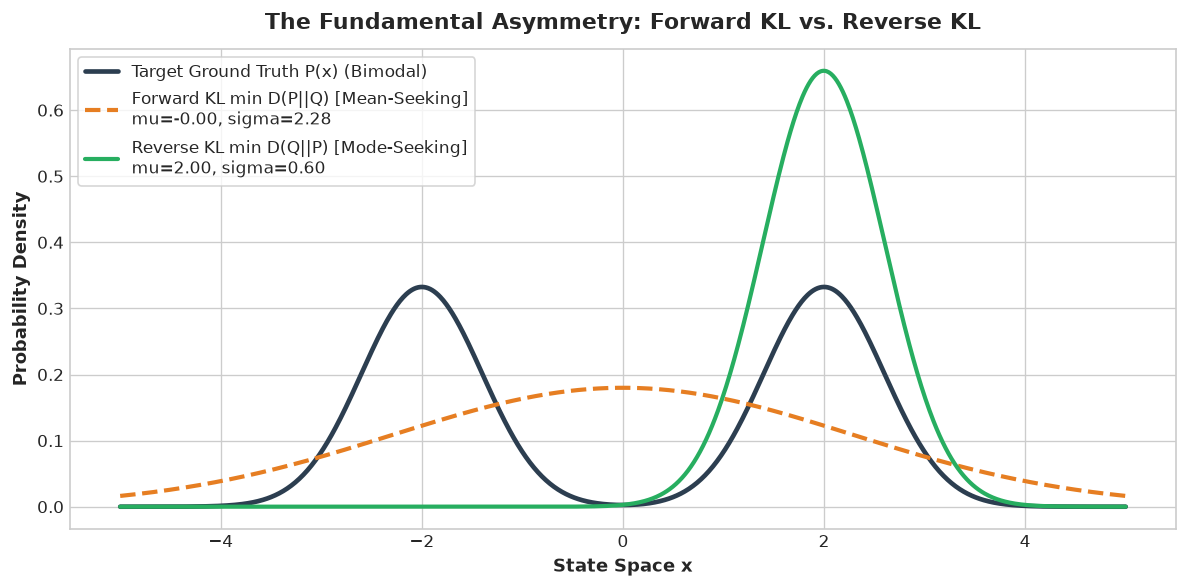

In [5]:
# Target bimodal distribution P(x)
x = np.linspace(-5, 5, 1000)
dx = x[1] - x[0]
p_bimodal = 0.5 * (1.0 / (np.sqrt(2 * np.pi) * 0.6)) * np.exp(-0.5 * ((x + 2.0) / 0.6)**2) + \
            0.5 * (1.0 / (np.sqrt(2 * np.pi) * 0.6)) * np.exp(-0.5 * ((x - 2.0) / 0.6)**2)
p_bimodal = p_bimodal / np.sum(p_bimodal * dx)

def gaussian(x, mu, sigma):
    g = (1.0 / (np.sqrt(2 * np.pi) * sigma)) * np.exp(-0.5 * ((x - mu) / sigma)**2)
    return g / np.sum(g * dx)

# Objective 1: Forward KL D_KL(P || Q)
def loss_forward(params):
    mu, sigma = params
    sigma = max(sigma, 0.1)
    q = gaussian(x, mu, sigma)
    # Integral p * log(p / q)
    mask = p_bimodal > 1e-15
    return np.sum(p_bimodal[mask] * np.log(p_bimodal[mask] / q[mask])) * dx

# Objective 2: Reverse KL D_KL(Q || P)
def loss_reverse(params):
    mu, sigma = params
    sigma = max(sigma, 0.1)
    q = gaussian(x, mu, sigma)
    mask = q > 1e-15
    return np.sum(q[mask] * np.log(q[mask] / p_bimodal[mask])) * dx

res_fwd = minimize(loss_forward, [0.0, 1.5], method='Nelder-Mead')
res_rev = minimize(loss_reverse, [1.8, 0.5], method='Nelder-Mead')

q_fwd = gaussian(x, res_fwd.x[0], res_fwd.x[1])
q_rev = gaussian(x, res_rev.x[0], res_rev.x[1])

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(x, p_bimodal, color='#2c3e50', lw=2.8, label='Target Ground Truth P(x) (Bimodal)')
ax.plot(x, q_fwd, color='#e67e22', lw=2.5, ls='--', 
        label=f'Forward KL min D(P||Q) [Mean-Seeking]\nmu={res_fwd.x[0]:.2f}, sigma={res_fwd.x[1]:.2f}')
ax.plot(x, q_rev, color='#27ae60', lw=2.5, 
        label=f'Reverse KL min D(Q||P) [Mode-Seeking]\nmu={res_rev.x[0]:.2f}, sigma={res_rev.x[1]:.2f}')

ax.set_xlabel("State Space x", fontsize=11, fontweight='bold')
ax.set_ylabel("Probability Density", fontsize=11, fontweight='bold')
ax.set_title("The Fundamental Asymmetry: Forward KL vs. Reverse KL", fontsize=13, fontweight='bold', pad=12)
ax.legend(frameon=True, fontsize=10)
plt.tight_layout()
plt.show()


---

## 6. 3-Tier Exercises & Explorations

### Tier 1: Warmup — The Penalty of Inverted Priors
Suppose a test has true failure rate $P(\text{Fail}) = 0.20$.
Calculate the relative entropy penalty $D_{\text{KL}}(P \parallel Q)$ if an engineer guesses:
1. $Q(\text{Fail}) = 0.10$
2. $Q(\text{Fail}) = 0.01$
3. $Q(\text{Fail}) = 0.001$
Observe how the penalty accelerates as $Q$ approaches zero.

### Tier 2: Intermediate — Symmetrized Divergence (Jensen-Shannon)
Because KL divergence is asymmetric, engineers often use the **Jensen-Shannon Divergence**:
$$D_{\text{JS}}(P \parallel Q) = \frac{1}{2} D_{\text{KL}}(P \parallel M) + \frac{1}{2} D_{\text{KL}}(Q \parallel M), \quad \text{where } M = \frac{1}{2}(P + Q)$$
Write a function `js_divergence(p, q)` and prove numerically that $D_{\text{JS}}(P \parallel Q) = D_{\text{JS}}(Q \parallel P)$ and that $\sqrt{D_{\text{JS}}}$ is bounded in $[0, 1]$.

### Tier 3: Advanced Research — Finding the Bayesian Compromise
Implement Arnold Zellner's Free Energy objective from Section 6 for a discrete parameter grid $\theta \in [0.01, 0.99]$.
Verify that the distribution $q^*(\theta)$ that minimizes:
$$\mathcal{F}[q] = D_{\text{KL}}(q \parallel P_{\text{prior}}) - \mathbb{E}_q[\ln P(\text{Data} \mid \theta)]$$
is numerically identical to the exact analytical posterior $P(\theta \mid \text{Data})$ computed via Bayes' Rule!


In [6]:
# Solution verification for Tier 1:
p_t1 = np.array([0.80, 0.20])
guesses = [0.10, 0.01, 0.001]

print("Tier 1 Solutions (True failure rate P = 0.20):")
for g in guesses:
    q_t1 = np.array([1.0 - g, g])
    dkl = kl_divergence(p_t1, q_t1)
    print(f"Guess Q = {g:<6}: D_KL(P || Q) = {dkl:.4f} bits/build")


Tier 1 Solutions (True failure rate P = 0.20):
Guess Q = 0.1   : D_KL(P || Q) = 0.0641 bits/build
Guess Q = 0.01  : D_KL(P || Q) = 0.6184 bits/build
Guess Q = 0.001 : D_KL(P || Q) = 1.2724 bits/build


---

**[Course Home](../README.md) | [Conceptual Track](../conceptual/02_relative_entropy_and_prior_penalties.ipynb) | [Prev: Ch 01: Quantifying Uncertainty (Python)](01_quantifying_uncertainty_entropy_and_bayes.ipynb) | [Next: Ch 03: Where Fleet Priors Come From (Python)](03_maximum_entropy_priors.ipynb)**
